# Combining Regions for H1 & CO

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import astropy.units as u
import os
import shutil
from astropy.io import fits # importing fits 
from astropy.utils.data import download_file # simple method of downloading FITS file 
from astropy.visualization import astropy_mpl_style # resource for organized plots
from astropy.visualization import ZScaleInterval, MinMaxInterval, AsinhStretch, LogStretch, ImageNormalize # quality image display/visualization
from astropy.wcs import WCS #coordinate conversion
from regions import Regions # import astropy region class
from regions import CompoundSkyRegion


## Spiral Arms, Disk, Bar, Arms

In [4]:
class DisplayData: 
    """" A class to open FITS file, display image data, 
         and plot a DS9.reg file onto the image data. """ 
    def __init__(self, filepath):
        """ Initialize through opening the data.""" 
        self.filepath = filepath
        from astropy.io import fits 
        with fits.open(filepath) as hdul: # opening file
            data = None
            header = None
            for hdu in hdul: #loops through each extension (HDU) in the list of HDUs to check if data has dimensions (thanks rav!)
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    break 
            
        if data is None:
            print("None")
       # hdu = fits.open(filepath)[1] #okay index 1 isn't always gong to work. you need to write an if statement to test 0


    def display_header(self, filepath):
        self.filepath = filepath
        from astropy.io import fits 
        with fits.open(filepath) as hdul:
            data = None
            header = None
            for hdu in hdul:
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    display(header)
                    break 
            
        if data is None:
            print("None")

    def display_image(self, filepath, norm, vmin, vmax):
        self.filepath = filepath 
        self.norm = norm
        self.vmin = vmin
        self.vmax = vmax
        #brightness control
        #hdu = fits.open(filepath)[1]
        #data = hdu.data
        #header = hdu.header 
        from astropy.io import fits
        with fits.open(filepath) as hdul:
            data = None
            header = None
            for hdu in hdul:
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    break 
            
        if data is None:
            print("None")



        plt.figure(figsize=(8, 8))
        plt.imshow(data, cmap="gray", origin="lower", norm=self.norm, vmin=self.vmin, vmax=self.vmax) #figure out a way to add normalization parameter into this function
        plt.colorbar(label="Intensity", fraction=0.0146, aspect=20)

      
            
    
    def plot_region(self, filepath, 

                    spiralarms1_regionfile, spiralarms2_regionfile,
                    norm, vmin, vmax, figname): 
        
        self.filepath = filepath
      
        
        self.spiralarms1_regionfile = spiralarms1_regionfile
        self.spiralarms2_regionfile = spiralarms2_regionfile

        self.norm = norm 
        self.vmin = vmin
        self.vmax= vmax 
        self.figname = figname
        from astropy.io import fits 
        from astropy.wcs import WCS
        with fits.open(filepath) as hdul:
            data = None
            header = None
            for hdu in hdul:
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    break 
            
        if data is None:
            print("None")
            
        wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        

        spiralarms_region1 = Regions.read(spiralarms1_regionfile)[0].to_pixel(wcs)  
        spiralarms_region11 = Regions.read(spiralarms1_regionfile)[1].to_pixel(wcs)
        spiralarms_region2 = Regions.read(spiralarms2_regionfile)[0].to_pixel(wcs)
        spiralarms_region22 = Regions.read(spiralarms2_regionfile)[1].to_pixel(wcs)
      

        fig, ax = plt.subplots(subplot_kw=dict(projection=wcs), dpi=150)
        darkorange_patch = mpatches.Patch(color='darkorange', label='CO') #https://matplotlib.org/stable/users/explain/axes/legend_guide.html
        lightorange_patch = mpatches.Patch(color='peachpuff', label='H1') #molecular gas tracers in orange

       
        
        
        
        
        ax.legend(handles=[darkorange_patch, lightorange_patch], loc='upper center', bbox_to_anchor=(0, -0.2), fontsize=5)
        ax.imshow(data, cmap='grey', origin='lower', norm=self.norm, vmin=self.vmin, vmax=self.vmax) 
        #https://docs.astropy.org/en/stable/visualization/wcsaxes/index.html
        overlay = ax.get_coords_overlay('fk5')
        overlay[0].set_axislabel('Right Ascension (J2000)')
        overlay[1].set_axislabel('Declination (J2000)')


        
        
       
        
        spiralarms_region1.plot(ax=ax, color='darkorange', lw=1.0)
        spiralarms_region11.plot(ax=ax, color='darkorange', lw=1.0)
        spiralarms_region2.plot(ax=ax, color= 'peachpuff', lw=1.0)
        spiralarms_region22.plot(ax=ax, color= 'peachpuff', lw=1.0)
        
        
        plt.savefig(figname, bbox_inches ='tight') #https://stackoverflow.com/questions/9651092/my-matplotlib-pyplot-legend-is-being-cut-off

    def plot_ringregion(self, filepath, 

                    ring1_regionfile, ring2_regionfile,
                    norm, vmin, vmax, figname): 
        
        self.filepath = filepath
      
        
        self.ring1_regionfile = ring1_regionfile
        self.ring2_regionfile = ring2_regionfile

        self.norm = norm 
        self.vmin = vmin
        self.vmax= vmax 
        self.figname = figname
        from astropy.io import fits 
        from astropy.wcs import WCS
        with fits.open(filepath) as hdul:
            data = None
            header = None
            for hdu in hdul:
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    break 
            
        if data is None:
            print("None")
            
        wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        

        ring_region1 = Regions.read(ring1_regionfile)[0].to_pixel(wcs)  
        ring_region11 = Regions.read(ring1_regionfile)[1].to_pixel(wcs)
        ring_region2 = Regions.read(ring2_regionfile)[0].to_pixel(wcs)
        ring_region22 = Regions.read(ring2_regionfile)[1].to_pixel(wcs)
      

        fig, ax = plt.subplots(subplot_kw=dict(projection=wcs), dpi=150)
        darkorange_patch = mpatches.Patch(color='darkorange', label='CO') #https://matplotlib.org/stable/users/explain/axes/legend_guide.html
        lightorange_patch = mpatches.Patch(color='peachpuff', label='H1') #molecular gas tracers in orange

       
        
        
        
        
        ax.legend(handles=[darkorange_patch, lightorange_patch], loc='upper center', bbox_to_anchor=(0, -0.2), fontsize=5)
        ax.imshow(data, cmap='grey', origin='lower', norm=self.norm, vmin=self.vmin, vmax=self.vmax) 
        #https://docs.astropy.org/en/stable/visualization/wcsaxes/index.html
        overlay = ax.get_coords_overlay('fk5')
        overlay[0].set_axislabel('Right Ascension (J2000)')
        overlay[1].set_axislabel('Declination (J2000)')


        
        
       
        
        ring_region1.plot(ax=ax, color='darkorange', lw=1.0)
        ring_region11.plot(ax=ax, color='darkorange', lw=1.0)
        ring_region2.plot(ax=ax, color= 'peachpuff', lw=1.0)
        ring_region22.plot(ax=ax, color= 'peachpuff', lw=1.0)
        
        
        plt.savefig(figname, bbox_inches ='tight') #https://stackoverflow.com/questions/9651092/my-matplotlib-pyplot-legend-is-being-cut-off

    def plot_barregion(self, filepath, 

                    bar1_regionfile, bar2_regionfile,
                    norm, vmin, vmax, figname): 
        
        self.filepath = filepath
      
        
        self.bar1_regionfile = bar1_regionfile
        self.bar2_regionfile = bar2_regionfile

        self.norm = norm 
        self.vmin = vmin
        self.vmax= vmax 
        self.figname = figname
        from astropy.io import fits 
        from astropy.wcs import WCS
        with fits.open(filepath) as hdul:
            data = None
            header = None
            for hdu in hdul:
                if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                    data = hdu.data 
                    header = hdu.header 
                    print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                    break 
            
        if data is None:
            print("None")
            
        wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        

        bar_region1 = Regions.read(bar1_regionfile)[0].to_pixel(wcs)  
        bar_region11 = Regions.read(bar1_regionfile)[1].to_pixel(wcs)
        bar_region2 = Regions.read(bar2_regionfile)[0].to_pixel(wcs)
        bar_region22 = Regions.read(bar2_regionfile)[1].to_pixel(wcs)
      

        fig, ax = plt.subplots(subplot_kw=dict(projection=wcs), dpi=150)
        darkorange_patch = mpatches.Patch(color='darkorange', label='CO') #https://matplotlib.org/stable/users/explain/axes/legend_guide.html
        lightorange_patch = mpatches.Patch(color='peachpuff', label='H1') #molecular gas tracers in orange

       
        
        
        
        
        ax.legend(handles=[darkorange_patch, lightorange_patch], loc='upper center', bbox_to_anchor=(0, -0.2), fontsize=5)
        ax.imshow(data, cmap='grey', origin='lower', norm=self.norm, vmin=self.vmin, vmax=self.vmax) 
        #https://docs.astropy.org/en/stable/visualization/wcsaxes/index.html
        overlay = ax.get_coords_overlay('fk5')
        overlay[0].set_axislabel('Right Ascension (J2000)')
        overlay[1].set_axislabel('Declination (J2000)')


        
        
       
        
        bar_region1.plot(ax=ax, color='darkorange', lw=1.0)
        bar_region11.plot(ax=ax, color='darkorange', lw=1.0)
        bar_region2.plot(ax=ax, color= 'peachpuff', lw=1.0)
        bar_region22.plot(ax=ax, color= 'peachpuff', lw=1.0)
        
        
        plt.savefig(figname, bbox_inches ='tight') #https://stackoverflow.com/questions/9651092/my-matplotlib-pyplot-legend-is-being-cut-off

    def plot_diskregion(self, filepath, 
    
                        disk1_regionfile, disk2_regionfile,
                        norm, vmin, vmax, figname): 
            
            self.filepath = filepath
          
            
            self.bar1_regionfile = disk1_regionfile
            self.bar2_regionfile = disk2_regionfile
    
            self.norm = norm 
            self.vmin = vmin
            self.vmax= vmax 
            self.figname = figname
            from astropy.io import fits 
            from astropy.wcs import WCS
            with fits.open(filepath) as hdul:
                data = None
                header = None
                for hdu in hdul:
                    if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
                        data = hdu.data 
                        header = hdu.header 
                        print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
                        break 
                
            if data is None:
                print("None")
                
            wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
            # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
            # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
            
    
            disk_region1 = Regions.read(disk1_regionfile)[0].to_pixel(wcs)  
            disk_region2 = Regions.read(disk2_regionfile)[0].to_pixel(wcs)
          
    
            fig, ax = plt.subplots(subplot_kw=dict(projection=wcs), dpi=150)
            darkorange_patch = mpatches.Patch(color='darkorange', label='CO') #https://matplotlib.org/stable/users/explain/axes/legend_guide.html
            lightorange_patch = mpatches.Patch(color='peachpuff', label='H1') #molecular gas tracers in orange
    
           
            
            
            
            
            ax.legend(handles=[darkorange_patch, lightorange_patch], loc='upper center', bbox_to_anchor=(0, -0.2), fontsize=5)
            ax.imshow(data, cmap='grey', origin='lower', norm=self.norm, vmin=self.vmin, vmax=self.vmax) 
            #https://docs.astropy.org/en/stable/visualization/wcsaxes/index.html
            overlay = ax.get_coords_overlay('fk5')
            overlay[0].set_axislabel('Right Ascension (J2000)')
            overlay[1].set_axislabel('Declination (J2000)')
    
    
            
            
           
            
            disk_region1.plot(ax=ax, color='darkorange', lw=1.0)
            disk_region2.plot(ax=ax, color= 'peachpuff', lw=1.0)
            
            
            plt.savefig(figname, bbox_inches ='tight') #https://stackoverflow.com/questions/9651092/my-matplotlib-pyplot-legend-is-being-cut-off
            
          

Found data in extension: HA6562_FLUX
Found data in extension: HA6562_FLUX


C:\Users\Lamat\AppData\Local\Programs\Python\Python314\Lib\site-packages\regions\shapes\polygon.py:225: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  return Polygon(xy=xy, **mpl_kwargs)


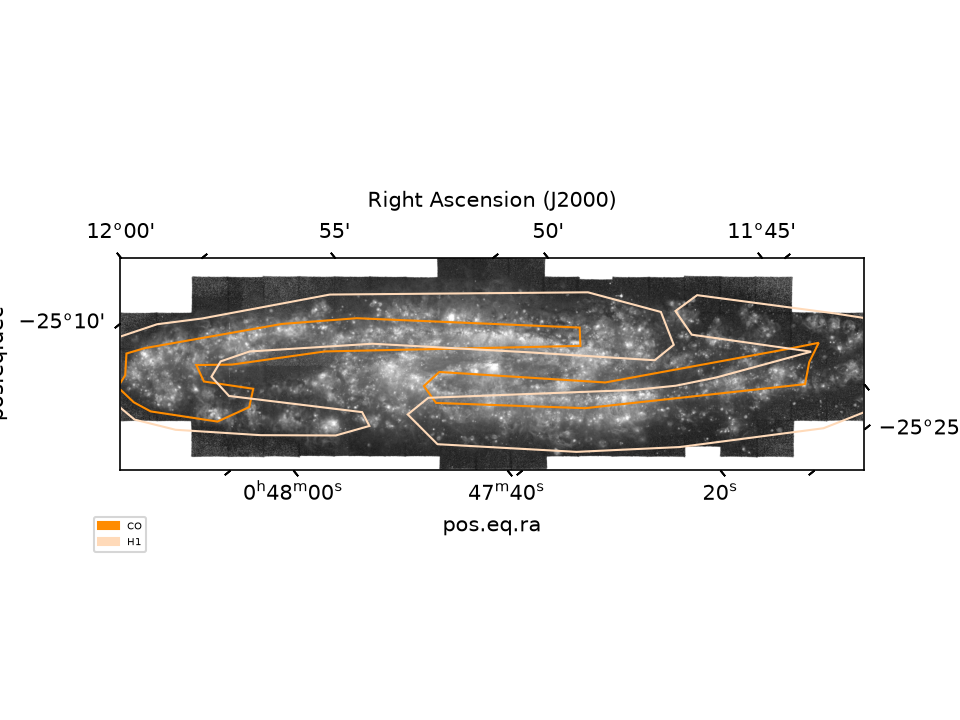

In [5]:
%matplotlib widget
ha_file = r"C:\Users\Lamat\OneDrive - The Ohio State University\Lamat NGC 253 Environment Mask\Plotting Regions\NGC0253_Ha.fits"
ha_data = DisplayData(ha_file)



co_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/DS9 NGC 253 Updated Region Files/Spiral Arms/spiralarms_co_regionfile_aca.reg"
h1_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/DS9 NGC 253 Updated Region Files/Spiral Arms/spiralarms_h1_regionfile_meerkat.reg"

co_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_co_regionfile_aca_thicker.reg"
h1_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_H1_regionfile_meerkatradio.reg"

co_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_co_regionfile_aca_twoboxes.reg"
h1_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_H1_regionfile_meerkatradio.reg"

co_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_co_regionfile_aca.reg"
h1_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_H1_regionfile_meerkatradio.reg"


ha_data.plot_region(ha_file, 
                    
                    co_spiralarms_regionfile, h1_spiralarms_regionfile,

                    norm = 'log', vmin=30, vmax=30000, figname='ha spiral arm regions - co & ha only')



## Mask for Compound Disk TEST

In [2]:
from astropy.io import fits 
from astropy.wcs import WCS

with fits.open(r"C:/Users/Lamat/OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/NGC0253_1_HI_subcube.image_mom0_2d.fits") as hdul:
    data = None
    header = None
    for hdu in hdul:
        if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
            data = hdu.data 
            header = hdu.header 
            print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
            break 
            
        if data is None:
            print("None")
            
wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        
co_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_co_regionfile_aca.reg"
h1_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_H1_regionfile_meerkatradio.reg"

co_disk_region1 = Regions.read(co_disk_regionfile)[0] 

h1_disk_region2 = Regions.read(h1_disk_regionfile)[0]




comp_region1 = co_disk_region1 & h1_disk_region2
comp_region2 = co_disk_region1 | h1_disk_region2


gas1 = comp_region1.to_pixel(wcs)



#gas_compregion1 = comp_region1
#gas_compregion2 = comp_region2

#gas_compregion1a = CompoundSkyRegion(co_spiralarms_region1, h1_spiralarms_region2).to_pixel(wcs)
#gas_compregion2a = CompoundSkyRegion(co_spiralarms_region11, h1_spiralarms_region22, operator=and).to_pixel(wcs)


#mask = gas1.to_mask(mode='center') #https://github.com/astropy/regions/issues/433
#np.count_nonzero(mask.data)

#mask_array = np.where((mask.to_image(data.shape)).astype(int) == 1,10000, 0)
#plt.imshow(mask_array)

        
        

Found data in extension: PRIMARY


## Mask for all environments CO, HI

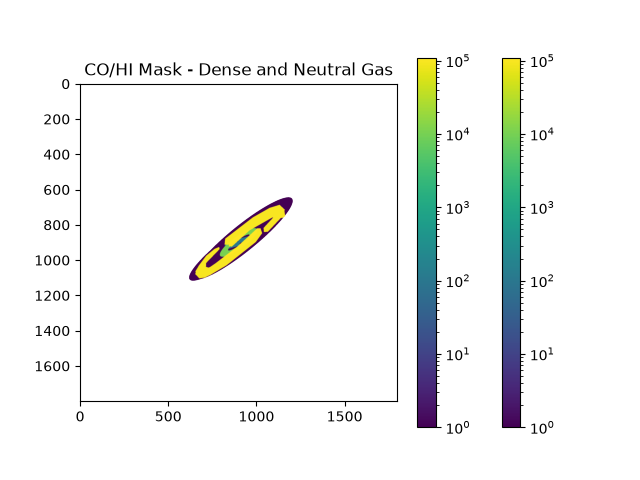

In [4]:
%matplotlib widget
co_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_co_regionfile_aca.reg"
h1_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_H1_regionfile_meerkatradio.reg"

co_disk_region1 = Regions.read(co_disk_regionfile)[0] 
h1_disk_region2 = Regions.read(h1_disk_regionfile)[0]


comp_diskregion = co_disk_region1 & h1_disk_region2
co_h1_disk = comp_diskregion.to_pixel(wcs)

comp_diskregion2 = co_disk_region1 | h1_disk_region2
co_h1_disk2 = comp_diskregion2.to_pixel(wcs)

disk_mask = co_h1_disk.to_mask(mode='center') #https://github.com/astropy/regions/issues/433, this basically helped me understand that it's hard to actually create a new .reg file for a comp region
disk_mask2 = co_h1_disk2.to_mask(mode='center')


co_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_co_regionfile_aca.reg"
h1_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_h1_regionfile_meerkat.reg"

co_spiralarms_region1 = Regions.read(co_spiralarms_regionfile)[0]
co_spiralarms_region11 = Regions.read(co_spiralarms_regionfile)[1]
h1_spiralarms_region2 = Regions.read(h1_spiralarms_regionfile)[0]
h1_spiralarms_region22 = Regions.read(h1_spiralarms_regionfile)[1]

comp_spiralregion1 = co_spiralarms_region1 & h1_spiralarms_region2 
comp_spiralregion2 = co_spiralarms_region11 & h1_spiralarms_region22
comp_spiralregion3 = co_spiralarms_region1 | h1_spiralarms_region2 
comp_spiralregion4 = co_spiralarms_region11 | h1_spiralarms_region22


co_h1_spiral1 = comp_spiralregion1.to_pixel(wcs)
co_h1_spiral2 = comp_spiralregion2.to_pixel(wcs)
co_h1_spiral3 = comp_spiralregion3.to_pixel(wcs)
co_h1_spiral4 = comp_spiralregion4.to_pixel(wcs)

spiral_mask1 = co_h1_spiral1.to_mask(mode='center')
spiral_mask2 = co_h1_spiral2.to_mask(mode='center')
spiral_mask3 = co_h1_spiral3.to_mask(mode='center')
spiral_mask4 = co_h1_spiral4.to_mask(mode='center')




co_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_co_regionfile_aca_thicker.reg"
h1_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_H1_regionfile_meerkatradio.reg"

co_ring_region1 = Regions.read(co_ring_regionfile)[0]
co_ring_region11 = Regions.read(co_ring_regionfile)[1]
h1_ring_region2 = Regions.read(h1_ring_regionfile)[0]
h1_ring_region22 = Regions.read(h1_ring_regionfile)[1]

comp_ringregion1 = co_ring_region1 & h1_ring_region2 
comp_ringregion2 = co_ring_region11 & h1_ring_region22
comp_ringregion3 = co_ring_region1 | h1_ring_region2 
comp_ringregion4 = co_ring_region11 | h1_ring_region22


co_h1_ring1 = comp_ringregion1.to_pixel(wcs)
co_h1_ring2 = comp_ringregion2.to_pixel(wcs)
co_h1_ring3 = comp_ringregion3.to_pixel(wcs)
co_h1_ring4 = comp_ringregion4.to_pixel(wcs)

ring_mask1 = co_h1_ring1.to_mask(mode='center')
ring_mask2 = co_h1_ring2.to_mask(mode='center')
ring_mask3 = co_h1_ring3.to_mask(mode='center')
ring_mask4 = co_h1_ring4.to_mask(mode='center')

outer = ring_mask1.to_image(data.shape)
inner = ring_mask2.to_image(data.shape)

outer1 = ring_mask3.to_image(data.shape)
inner1 = ring_mask4.to_image(data.shape)

annulus_mask = (outer > 0) & (inner == 0)
annulus_mask = (outer1 > 0) & (inner1 == 0)


co_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_co_regionfile_aca_twoboxes.reg"
h1_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_H1_regionfile_meerkatradio.reg"

co_bar_region1 = Regions.read(co_bar_regionfile)[0]
co_bar_region11 = Regions.read(co_bar_regionfile)[1]
h1_bar_region2 = Regions.read(h1_bar_regionfile)[0]
h1_bar_region22 = Regions.read(h1_bar_regionfile)[1]

comp_barregion1 = co_bar_region1 & h1_bar_region2 
comp_barregion2 = co_bar_region11 & h1_bar_region22
comp_barregion3 = co_bar_region1 | h1_bar_region2 
comp_barregion4 = co_bar_region11 | h1_bar_region22

co_h1_bar1 = comp_barregion1.to_pixel(wcs)
co_h1_bar2 = comp_barregion2.to_pixel(wcs)
co_h1_bar3 = comp_barregion3.to_pixel(wcs)
co_h1_bar4 = comp_barregion4.to_pixel(wcs)

bar_mask1 = co_h1_bar1.to_mask(mode='center')
bar_mask2 = co_h1_bar2.to_mask(mode='center')
bar_mask3 = co_h1_bar3.to_mask(mode='center')
bar_mask4 = co_h1_bar4.to_mask(mode='center')



co_center_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/center_co_regionfile_aca.reg"
co_center_region = Regions.read(co_center_regionfile)[0]

co_center = co_center_region.to_pixel(wcs)

center_mask = co_center.to_mask(mode='center')


mask_array = np.where((ring_mask1.to_image(data.shape)).astype(int) == 1,10000, 0)

mask_array = np.where((ring_mask2.to_image(data.shape)).astype(int) == 1, 0, mask_array)

mask_array = np.where((disk_mask.to_image(data.shape)).astype(int) == 1, mask_array+1, 0) #disk, where the disk mask=1, assign pixel value 1 to the overall mask array

mask_array = np.where((spiral_mask1.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) #spiral arm 1

mask_array = np.where((spiral_mask2.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) # spiral arm 2

mask_array = np.where((bar_mask1.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((bar_mask2.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((center_mask.to_image(data.shape)).astype(int) == 1, mask_array+1000000, mask_array)



mask_array = np.where((ring_mask3.to_image(data.shape)).astype(int) == 1,10000, 0)

mask_array = np.where((ring_mask4.to_image(data.shape)).astype(int) == 1, 0, mask_array)

mask_array = np.where((disk_mask2.to_image(data.shape)).astype(int) == 1, mask_array+1, 0) #disk, where the disk mask=1, assign pixel value 1 to the overall mask array

mask_array = np.where((spiral_mask3.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) #spiral arm 1

mask_array = np.where((spiral_mask4.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) # spiral arm 2

mask_array = np.where((bar_mask3.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((bar_mask4.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)




plt.imshow(mask_array, norm='log')
plt.colorbar()
plt.title('CO/HI Mask - Dense and Neutral Gas')
plt.savefig('CO_HI Mask_Dense and Neutral Gas')
plt.show()


In [7]:
hdu = fits.PrimaryHDU(data = mask_array)
print(hdu)
#hdu.header = header
#wcs2 = WCS(header)
#print(wcs2)
hdu.writeto('coh1_mask.fits', overwrite=True)

## Messy Incorrect Code

Found data in extension: PRIMARY


C:\Users\Lamat\AppData\Local\Programs\Python\Python314\Lib\site-packages\regions\shapes\polygon.py:225: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  return Polygon(xy=xy, **mpl_kwargs)


AttributeError: 'PolygonPixelRegion' object has no attribute 'center'

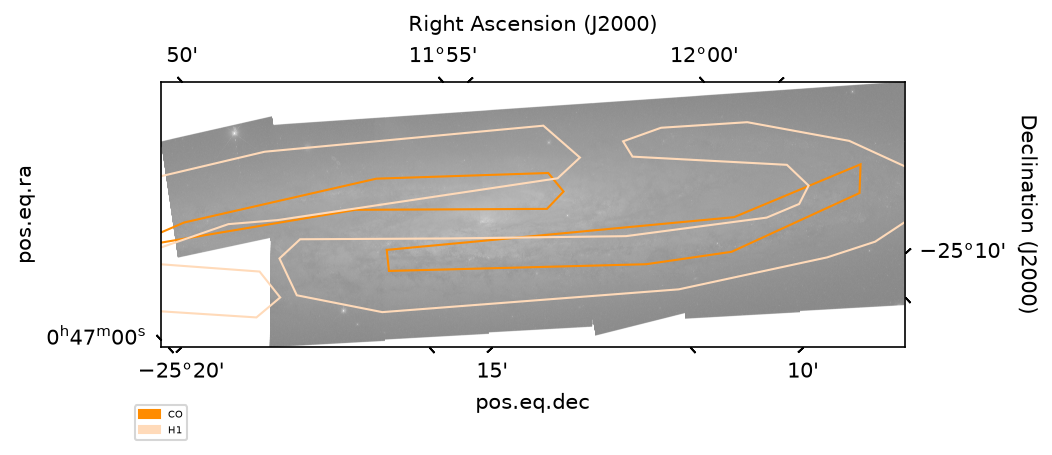

In [20]:
#%matplotlib widget
#ha_file = r"C:\Users\Lamat\OneDrive - The Ohio State University\Lamat NGC 253 Environment Mask\Plotting Regions\NGC0253_Ha.fits"
#ha_data = DisplayData(ha_file)


from astropy.io import fits 
from astropy.wcs import WCS

with fits.open(r"C:/Users/Lamat/OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/NGC0253V2_Ha.fits") as hdul:
    data = None
    header = None
    for hdu in hdul:
        if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
            data = hdu.data 
            header = hdu.header 
            print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
            break 
            
        if data is None:
            print("None")
            
wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        
co_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_co_regionfile_aca.reg"
h1_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_h1_regionfile_meerkat.reg"

co_spiralarms_region1 = Regions.read(co_spiralarms_regionfile)[0] 
co_spiralarms_region11 = Regions.read(co_spiralarms_regionfile)[1]

h1_spiralarms_region2 = Regions.read(h1_spiralarms_regionfile)[0]
h1_spiralarms_region22 = Regions.read(h1_spiralarms_regionfile)[1]



comp_region1 = co_spiralarms_region1 & h1_spiralarms_region2
comp_region2 = co_spiralarms_region11 & h1_spiralarms_region22

gas1 = comp_region1.to_pixel(wcs)
gas2 = comp_region2.to_pixel(wcs)

#gas_compregion1 = comp_region1
#gas_compregion2 = comp_region2

#gas_compregion1a = CompoundSkyRegion(co_spiralarms_region1, h1_spiralarms_region2).to_pixel(wcs)
#gas_compregion2a = CompoundSkyRegion(co_spiralarms_region11, h1_spiralarms_region22, operator=and).to_pixel(wcs)


co_spiralarms_region1a = Regions.read(co_spiralarms_regionfile)[0].to_pixel(wcs) 
co_spiralarms_region11a = Regions.read(co_spiralarms_regionfile)[1].to_pixel(wcs)

h1_spiralarms_region2a = Regions.read(h1_spiralarms_regionfile)[0].to_pixel(wcs)
h1_spiralarms_region22a = Regions.read(h1_spiralarms_regionfile)[1].to_pixel(wcs)


fig, ax = plt.subplots(subplot_kw=dict(projection=wcs), dpi=150)
darkorange_patch = mpatches.Patch(color='darkorange', label='CO') #https://matplotlib.org/stable/users/explain/axes/legend_guide.html
lightorange_patch = mpatches.Patch(color='peachpuff', label='H1') #molecular gas tracers in orange
    
        
ax.legend(handles=[darkorange_patch, lightorange_patch], loc='upper center', bbox_to_anchor=(0, -0.2), fontsize=5)
ax.imshow(data, cmap='grey', origin='lower', norm='log')
        #https://docs.astropy.org/en/stable/visualization/wcsaxes/index.html
overlay = ax.get_coords_overlay('fk5')
overlay[0].set_axislabel('Right Ascension (J2000)')
overlay[1].set_axislabel('Declination (J2000)')


        
        
       
co_spiralarms_region1a.plot(ax=ax, color='darkorange', lw=1.0)
co_spiralarms_region11a.plot(ax=ax, color='darkorange', lw=1.0)
h1_spiralarms_region2a.plot(ax=ax, color= 'peachpuff', lw=1.0)
h1_spiralarms_region22a.plot(ax=ax, color= 'peachpuff', lw=1.0)
gas1.plot(ax=ax, color='green', lw=1.0)
gas2.plot(ax=ax, color='green', lw=1.0)
        
        



In [12]:
from astropy.io import fits 
from astropy.wcs import WCS

with fits.open(r"C:/Users/Lamat/OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/NGC0253V2_Ha.fits") as hdul:
    data = None
    header = None
    for hdu in hdul:
        if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
            data = hdu.data 
            header = hdu.header 
            print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
            break 
            
        if data is None:
            print("None")
            
wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        
co_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_co_regionfile_aca.reg"
h1_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_H1_regionfile_meerkatradio.reg"

co_disk_region1 = Regions.read(co_disk_regionfile)[0]

h1_disk_region2 = Regions.read(h1_disk_regionfile)[0]




comp_region1 = co_disk_region1 & h1_disk_region2


gas1 = comp_region1.to_pixel(wcs)
mask = gas1.to_mask(mode='center')
np.count_nonzero(mask.data)


Found data in extension: PRIMARY


np.int64(163054729)

In [ ]:
from astropy.io import fits 
from astropy.wcs import WCS

with fits.open(r"C:/Users/Lamat/OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/NGC0253V2_Ha.fits") as hdul:
    data = None
    header = None
    for hdu in hdul:
        if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
            data = hdu.data 
            header = hdu.header 
            print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
            break 
            
        if data is None:
            print("None")
            
wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region
        
co_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_co_regionfile_aca.reg"
h1_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_H1_regionfile_meerkatradio.reg"

co_disk_region1 = Regions.read(co_disk_regionfile)[0] 

h1_disk_region2 = Regions.read(h1_disk_regionfile)[0]




comp_region1 = co_disk_region1 & h1_disk_region2


gas1 = comp_region1.to_pixel(wcs)

In [ ]:
from astropy.coordinates import Angle, SkyCoord
from regions import CircleSkyRegion
from astropy.wcs.utils import pixel_to_skycoord, skycoord_to_pixel
from astropy.regions import CirclePixelRegion, CircleSkyRegion
import astropy.units as u


co_skycoord = astropy.wcs.utils.pixel_to_skycoord(495,565,wcs)


